# GIAI ĐOẠN 6: PHÂN TÍCH ĐỀ XUẤT, PHÂN KHÚC 4 GÓC PHẦN TƯ & LỢI NHUẬN RÒNG ĐA TẦNG
## Prescriptive Analytics: Ma trận Giá trị × Rủi ro, Next-Best-Action & Mô hình Tài chính ROI
### Doanh nghiệp giả định: EuroVanguard Bank (France, Germany, Spain)
**Quy trình chuẩn:** Gartner Level 4 — Prescriptive Analytics (Tầng Phân tích Đề xuất Hành động)

---
### Các Trọng tâm Kỹ thuật:
1. **Ma trận Phân khúc 4 Góc Phần tư (Value × Risk 4-Quadrants Matrix):** Tách bạch rõ rệt giữa Giá trị Tiền gửi (Vốn huy động) và Mức độ Rủi ro Rời bỏ để phân bổ nguồn lực giữ chân tối ưu.
2. **Động cơ Hành động Tiếp theo Tối ưu (Next-Best-Action Engine):** Tự động đề xuất gói can thiệp giữ chân cá nhân hóa dựa trên căn nguyên hành vi thực tế (Khiếu nại, Bẫy bán chéo, Chi nhánh Đức, Bất hoạt kênh số).
3. **Bộ sinh Kịch bản Cuộc gọi Động (Dynamic Front-line Call Script Generator):** Tạo kịch bản tiếp cận chuyên nghiệp, ấm áp, bảo mật cho Chuyên viên Quản lý Quan hệ Khách hàng (RM).
4. **Mô hình Mô phỏng Lợi nhuận Ròng Đa tầng (Tiered Financial ROI Calculator):** Tính toán chi phí can thiệp, tỷ lệ thành công và lợi nhuận ròng kỳ vọng (Net Gain) cho từng phân khúc và toàn bộ danh mục ngân hàng.


## 1. Thiết lập Môi trường & Nạp Module Dự án

In [1]:
import os
import sys

# Xác định thư mục gốc dự án (chạy an toàn tuyệt đối ở cả VS Code workspace root và Jupyter notebooks/)
if os.path.exists('src'):
    PROJECT_ROOT = os.path.abspath('.')
elif os.path.exists(os.path.join('..', 'src')):
    PROJECT_ROOT = os.path.abspath('..')
else:
    PROJECT_ROOT = os.path.abspath('.')

if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

import os
import sys
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('ggplot')
%matplotlib inline

FIGURES_DIR = os.path.join(PROJECT_ROOT, 'reports', 'figures')
os.makedirs(FIGURES_DIR, exist_ok=True)

from src.modeling.predict import predict_batch
from src.business.segmentation import assign_four_quadrants, get_quadrant_summary
from src.business.retention_advisor import (
    recommend_next_best_action,
    generate_call_script,
    calculate_tiered_roi
)

# Nạp mô hình quán quân và dữ liệu toàn diện
PIPELINE_PATH = os.path.join(PROJECT_ROOT, 'models', 'churn_early_warning_pipeline.joblib')
pipeline = joblib.load(PIPELINE_PATH)

DATA_PATH = os.path.join(PROJECT_ROOT, 'data', 'processed', 'full_engineered.csv')
df = pd.read_csv(DATA_PATH)

print(f"Đã nạp Pipeline: {type(pipeline.named_steps['classifier']).__name__}")
print(f"Đã nạp Dữ liệu: {df.shape[0]:,} dòng x {df.shape[1]} cột")


Đã nạp Pipeline: XGBClassifier
Đã nạp Dữ liệu: 10,000 dòng x 25 cột


## 2. Tính Điểm Rủi ro & Phân khúc Ma trận 4 Góc Phần tư (Value × Risk)

In [2]:
# 1. Tính toán xác suất và phân tầng rủi ro bằng pipeline
df_scored = predict_batch(pipeline, df, threshold=0.45, enforce_complain_rule=True)

# 2. Phân loại vào 4 góc phần tư
df_quadrants = assign_four_quadrants(
    df_scored,
    prob_col='Predicted_Probability',
    balance_col='Balance',
    risk_threshold=0.45,
    high_value_threshold=80000.0
)

# 3. Tổng hợp KPI theo từng góc phần tư
quadrant_summary = get_quadrant_summary(df_quadrants)
print("=== BẢNG TỔNG HỢP KPI PHÂN KHÚC 4 GÓC PHẦN TƯ ===")
display(quadrant_summary)


=== BẢNG TỔNG HỢP KPI PHÂN KHÚC 4 GÓC PHẦN TƯ ===


,Quadrant_Code,Description,Customer_Count,Customer_Pct,Total_Balance_M_EUR,Balance_Pct,Mean_Balance_EUR,Avg_Predicted_Risk_Pct,Actual_Churn_Pct
0,Q1_VIP_At_Risk,"VIP Nguy cơ Cao (High Value, High Risk)",1899,18.99,242.81,31.75,127863.67,90.180000,74.14
1,Q2_Standard_At_Risk,"Phổ thông Nguy cơ Cao (Low Value, High Risk)",754,7.54,9.32,1.22,12358.96,93.349998,83.29
2,Q3_VIP_Loyal,"VIP Trung thành (High Value, Low Risk)",3899,38.99,483.73,63.24,124064.85,16.000000,0.03
3,Q4_Standard_Loyal,"Phổ thông Trung thành (Low Value, Low Risk)",3448,34.48,29.00,3.79,8410.18,13.420000,0.03


### 2.1. Trực quan hóa Ma trận 4 Góc Phần tư

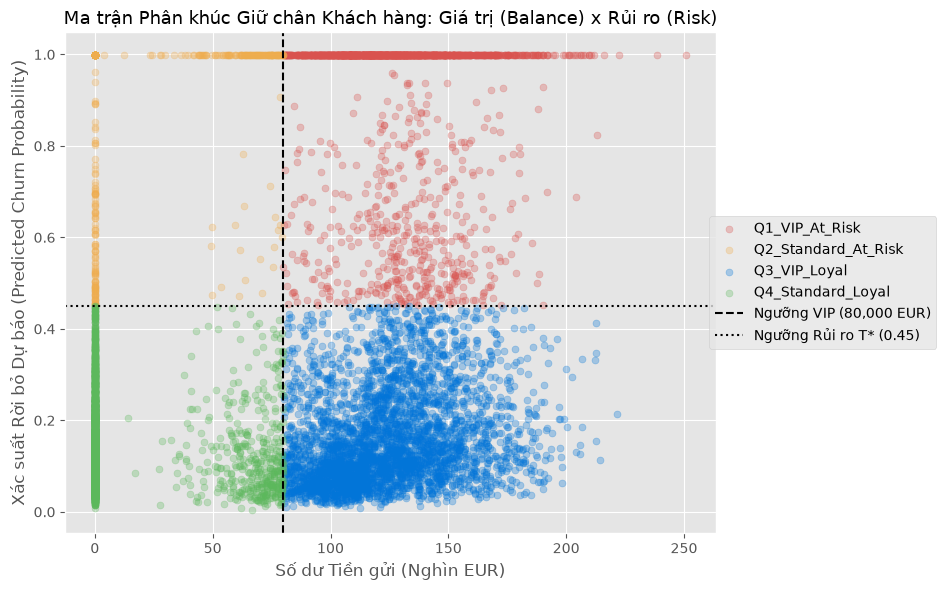

In [3]:
plt.figure(figsize=(10, 6))

colors = {
    'Q1_VIP_At_Risk': '#d9534f',       # Đỏ: Nguy hiểm nhất
    'Q2_Standard_At_Risk': '#f0ad4e',  # Cam: Rủi ro phổ thông
    'Q3_VIP_Loyal': '#0275d8',         # Xanh dương: Khách VIP giữ chân
    'Q4_Standard_Loyal': '#5cb85c'     # Xanh lá: Khách phổ thông an toàn
}

for q_name, color in colors.items():
    sub = df_quadrants[df_quadrants['Quadrant'] == q_name]
    plt.scatter(
        sub['Balance'] / 1e3,
        sub['Predicted_Probability'],
        label=q_name,
        color=color,
        alpha=0.3,
        s=25
    )

plt.axvline(x=80.0, color='black', linestyle='--', linewidth=1.5, label='Ngưỡng VIP (80,000 EUR)')
plt.axhline(y=0.45, color='black', linestyle=':', linewidth=1.5, label='Ngưỡng Rủi ro T* (0.45)')

plt.title("Ma trận Phân khúc Giữ chân Khách hàng: Giá trị (Balance) x Rủi ro (Risk)", fontsize=13)
plt.xlabel("Số dư Tiền gửi (Nghìn EUR)")
plt.ylabel("Xác suất Rời bỏ Dự báo (Predicted Churn Probability)")
plt.legend(loc='center right', bbox_to_anchor=(1.35, 0.5))
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'fig_17_four_quadrants_matrix.png'), dpi=300, bbox_inches='tight')
plt.show()


## 3. Thử nghiệm Động cơ Đề xuất Hành động Tối ưu (Next-Best-Action Engine)
Áp dụng thử nghiệm trên 4 hồ sơ khách hàng đại diện cho các phân khúc hành vi rủi ro then chốt:


In [4]:
sample_profiles = [
    {
        'Profile_Name': 'Hồ sơ 1: Khách hàng Đức có Số dư Lớn (German Wealth Outflow)',
        'data': {
            'CustomerId': 15700001, 'Surname': 'Müller', 'Gender': 'Male',
            'Geography': 'Germany', 'Tenure': 5, 'Balance': 145000.0,
            'NumOfProducts': 2, 'IsActiveMember': 1, 'Complain': 0
        }
    },
    {
        'Profile_Name': 'Hồ sơ 2: Khách hàng Rơi vào Bẫy Bán chéo Quá mức (Over-bundled Trap)',
        'data': {
            'CustomerId': 15700002, 'Surname': 'Dubois', 'Gender': 'Female',
            'Geography': 'France', 'Tenure': 3, 'Balance': 65000.0,
            'NumOfProducts': 4, 'IsActiveMember': 1, 'Complain': 0
        }
    },
    {
        'Profile_Name': 'Hồ sơ 3: Khách hàng Phát sinh Khiếu nại Chưa giải quyết (Emergency Complaint)',
        'data': {
            'CustomerId': 15700003, 'Surname': 'Schneider', 'Gender': 'Male',
            'Geography': 'Germany', 'Tenure': 2, 'Balance': 95000.0,
            'NumOfProducts': 1, 'IsActiveMember': 1, 'Complain': 1
        }
    },
    {
        'Profile_Name': 'Hồ sơ 4: Khách hàng Bất hoạt Kênh số (Digital Inactive)',
        'data': {
            'CustomerId': 15700004, 'Surname': 'Fernandez', 'Gender': 'Female',
            'Geography': 'Spain', 'Tenure': 6, 'Balance': 40000.0,
            'NumOfProducts': 1, 'IsActiveMember': 0, 'Complain': 0
        }
    }
]

for p in sample_profiles:
    nba = recommend_next_best_action(p['data'])
    print(f"\n{'='*70}")
    print(f"[{p['Profile_Name']}]")
    print(f"Khách hàng: {p['data']['Surname']} ({p['data']['Geography']}) | Số dư: {p['data']['Balance']:,.2f} EUR")
    print(f" -> Mã chiến lược: {nba['strategy_code']} (Mức độ: {nba['urgency']})")
    print(f" -> Tên chiến lược: {nba['strategy_name']}")
    print(f" -> Hành động đề xuất: {nba['recommended_action']}")
    print(f" -> Kênh tiếp cận: {nba['channel']} (Chi phí dự kiến: {nba['estimated_cost_eur']} EUR)")



[Hồ sơ 1: Khách hàng Đức có Số dư Lớn (German Wealth Outflow)]
Khách hàng: Müller (Germany) | Số dư: 145,000.00 EUR
 -> Mã chiến lược: S3_GERMAN_WEALTH_LOCK (Mức độ: CAO (HIGH))
 -> Tên chiến lược: Đặc quyền Bảo toàn Vốn Chi nhánh Đức (German Wealth Protection)
 -> Hành động đề xuất: Khách hàng Müller đang duy trì số dư lớn (145,000.00 EUR) tại chi nhánh Đức. Đề xuất gói tiền gửi kỳ hạn linh hoạt với lãi suất cộng thêm ưu đãi +0.50%/năm để cạnh tranh trực tiếp với ngân hàng nội địa, miễn phí dịch vụ chuyển tiền quốc tế, và chỉ định Private Banker quản lý riêng.
 -> Kênh tiếp cận: Chuyên viên Quản lý Tài sản (Wealth Manager / Private Banker) (Chi phí dự kiến: 150.0 EUR)

[Hồ sơ 2: Khách hàng Rơi vào Bẫy Bán chéo Quá mức (Over-bundled Trap)]
Khách hàng: Dubois (France) | Số dư: 65,000.00 EUR
 -> Mã chiến lược: S2_PRODUCT_RATIONALIZATION (Mức độ: CAO (HIGH))
 -> Tên chiến lược: Gỡ bẫy Bán chéo: Hợp nhất & Tinh gọn Gói Sản phẩm
 -> Hành động đề xuất: Rà soát danh mục 4 sản phẩm của khách 

## 4. Bộ sinh Kịch bản Cuộc gọi Chăm sóc Khách hàng Cá nhân hóa (Call Script Generator)

In [5]:
# Tạo kịch bản mẫu cho khách hàng Đức có số dư lớn
sample_cust = sample_profiles[0]['data']
call_script_text = generate_call_script(sample_cust, rm_name="Nguyễn Văn Bảo")
print(call_script_text)


KỊCH BẢN CHĂM SÓC KHÁCH HÀNG CÁ NHÂN HÓA (FRONT-LINE RETENTION CALL SCRIPT)
Ngân hàng: EuroVanguard Bank | Khách hàng: Anh Müller | Chi nhánh: Germany
Chuyên viên phụ trách: Nguyễn Văn Bảo | Mã chiến lược: S3_GERMAN_WEALTH_LOCK
Mức độ ưu tiên: CAO (HIGH) | Kênh thực hiện: Chuyên viên Quản lý Tài sản (Wealth Manager / Private Banker)

[BƯỚC 1: LỜI CHÀO & TẠO SỰ GẮN KẾT ẤM ÁP]
"Dạ, em chào Anh Müller! Em là Nguyễn Văn Bảo, Chuyên viên Quản lý Quan hệ Khách hàng tại EuroVanguard Bank chi nhánh Germany.
Trước hết, thay mặt ban lãnh đạo ngân hàng, em xin chân thành cảm ơn Anh đã đồng hành và tin tưởng gắn bó cùng EuroVanguard trong suốt 5 năm qua.
Hôm nay em liên hệ trực tiếp để kiểm tra xem quá trình trải nghiệm dịch vụ tài khoản của Anh có điều gì cần ngân hàng hỗ trợ thêm hay không ạ?"

[BƯỚC 2: TIẾP CẬN TẾ NHỊ DỰA TRÊN ĐẶC TRƯNG HÀNH VI]
"Dạ thưa Anh, với tư cách là một trong những khách hàng tiền gửi tiêu biểu tại chi nhánh Đức, ngân hàng chúng em trân trọng mời Anh tham gia gói đặc qu

## 5. Mô phỏng Lợi nhuận Ròng Tài chính Đa tầng (Tiered Financial ROI Calculator)
**Cấu trúc mô hình tài chính:**
- **Phân khúc Q1 (VIP At-Risk):** Chi phí can thiệp 150 EUR/khách (Private Banker liên hệ trực tiếp); Tỷ lệ giữ chân thành công kỳ vọng = **40%**.
- **Phân khúc Q2 (Standard At-Risk):** Chi phí can thiệp 25 EUR/khách (Kênh số/App/Email tự động); Tỷ lệ giữ chân thành công kỳ vọng = **25%**.
- **Biên lợi nhuận ngân hàng:** 5% trên số dư tiền gửi bảo toàn hàng năm + 200 EUR phí dịch vụ cơ sở.


In [6]:
roi_results = calculate_tiered_roi(
    df_quadrants,
    vip_cost=150.0,
    std_cost=25.0,
    vip_save_rate=0.40,
    std_save_rate=0.25,
    margin_rate=0.05,
    base_service_fee=200.0
)

# Chuyển đổi thành bảng so sánh trực quan
roi_table = pd.DataFrame([
    {
        'Phân khúc Chiến dịch': 'Q1: VIP Nguy cơ Cao (High Value, High Risk)',
        'Số khách Tiếp cận': f"{roi_results['Q1_VIP']['targeted_count']:,}",
        'Tổng Chi phí Can thiệp': f"{roi_results['Q1_VIP']['intervention_cost_eur']:,.2f} EUR",
        'Số khách Giữ chân Dự kiến': f"{roi_results['Q1_VIP']['expected_customers_saved']:,.1f}",
        'Tiền gửi Giữ lại (M EUR)': f"{roi_results['Q1_VIP']['deposit_volume_saved_m_eur']:.2f}M EUR",
        'Giá trị CLV Bảo toàn': f"{roi_results['Q1_VIP']['clv_value_saved_eur']:,.2f} EUR",
        'Lợi nhuận Ròng (Net Gain)': f"{roi_results['Q1_VIP']['net_profit_eur']:,.2f} EUR",
        'Hệ số ROI (%)': f"{roi_results['Q1_VIP']['roi_pct']:.1f}%"
    },
    {
        'Phân khúc Chiến dịch': 'Q2: Phổ thông Nguy cơ Cao (Low Value, High Risk)',
        'Số khách Tiếp cận': f"{roi_results['Q2_Standard']['targeted_count']:,}",
        'Tổng Chi phí Can thiệp': f"{roi_results['Q2_Standard']['intervention_cost_eur']:,.2f} EUR",
        'Số khách Giữ chân Dự kiến': f"{roi_results['Q2_Standard']['expected_customers_saved']:,.1f}",
        'Tiền gửi Giữ lại (M EUR)': f"{roi_results['Q2_Standard']['deposit_volume_saved_m_eur']:.2f}M EUR",
        'Giá trị CLV Bảo toàn': f"{roi_results['Q2_Standard']['clv_value_saved_eur']:,.2f} EUR",
        'Lợi nhuận Ròng (Net Gain)': f"{roi_results['Q2_Standard']['net_profit_eur']:,.2f} EUR",
        'Hệ số ROI (%)': f"{roi_results['Q2_Standard']['roi_pct']:.1f}%"
    },
    {
        'Phân khúc Chiến dịch': 'TOÀN BỘ CHIẾN DỊCH (TOTAL PORTFOLIO)',
        'Số khách Tiếp cận': f"{roi_results['Total_Campaign']['total_targeted_count']:,}",
        'Tổng Chi phí Can thiệp': f"{roi_results['Total_Campaign']['total_intervention_cost_eur']:,.2f} EUR",
        'Số khách Giữ chân Dự kiến': f"{roi_results['Total_Campaign']['total_customers_saved']:,.1f}",
        'Tiền gửi Giữ lại (M EUR)': f"{roi_results['Total_Campaign']['total_deposit_saved_m_eur']:.2f}M EUR",
        'Giá trị CLV Bảo toàn': f"{roi_results['Total_Campaign']['total_clv_saved_eur']:,.2f} EUR",
        'Lợi nhuận Ròng (Net Gain)': f"{roi_results['Total_Campaign']['total_net_profit_eur']:,.2f} EUR",
        'Hệ số ROI (%)': f"{roi_results['Total_Campaign']['total_roi_pct']:.1f}%"
    }
])

display(roi_table)


,Phân khúc Chiến dịch,Số khách Tiếp cận,Tổng Chi phí Can thiệp,Số khách Giữ chân Dự kiến,Tiền gửi Giữ lại (M EUR),Giá trị CLV Bảo toàn,Lợi nhuận Ròng (Net Gain),Hệ số ROI (%)
0,"Q1: VIP Nguy cơ Cao (High Value, High Risk)","1,899","284,850.00 EUR",563.2,72.01M EUR,"3,713,280.86 EUR","3,428,430.86 EUR",1203.6%
1,"Q2: Phổ thông Nguy cơ Cao (Low Value, High Risk)",754,"18,850.00 EUR",157.0,1.94M EUR,"128,417.81 EUR","109,567.81 EUR",581.3%
2,TOÀN BỘ CHIẾN DỊCH (TOTAL PORTFOLIO),"2,653","303,700.00 EUR",720.2,73.95M EUR,"3,841,698.67 EUR","3,537,998.67 EUR",1165.0%


### 5.1. Trực quan hóa Cấu trúc Tài chính ROI Đa tầng

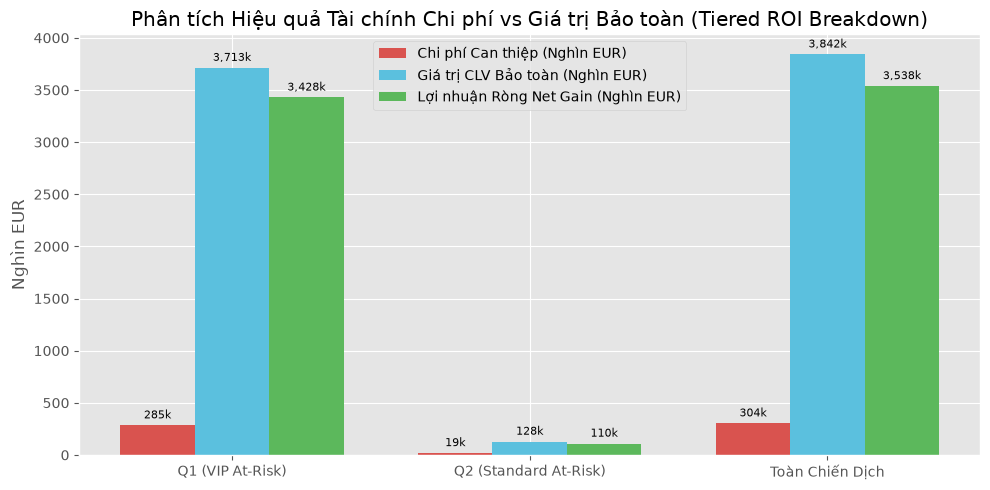

In [7]:
categories = ['Q1 (VIP At-Risk)', 'Q2 (Standard At-Risk)', 'Toàn Chiến Dịch']
costs = [
    roi_results['Q1_VIP']['intervention_cost_eur'] / 1e3,
    roi_results['Q2_Standard']['intervention_cost_eur'] / 1e3,
    roi_results['Total_Campaign']['total_intervention_cost_eur'] / 1e3
]
values = [
    roi_results['Q1_VIP']['clv_value_saved_eur'] / 1e3,
    roi_results['Q2_Standard']['clv_value_saved_eur'] / 1e3,
    roi_results['Total_Campaign']['total_clv_saved_eur'] / 1e3
]
profits = [
    roi_results['Q1_VIP']['net_profit_eur'] / 1e3,
    roi_results['Q2_Standard']['net_profit_eur'] / 1e3,
    roi_results['Total_Campaign']['total_net_profit_eur'] / 1e3
]

x = np.arange(len(categories))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 5))
rects1 = ax.bar(x - width, costs, width, label='Chi phí Can thiệp (Nghìn EUR)', color='#d9534f')
rects2 = ax.bar(x, values, width, label='Giá trị CLV Bảo toàn (Nghìn EUR)', color='#5bc0de')
rects3 = ax.bar(x + width, profits, width, label='Lợi nhuận Ròng Net Gain (Nghìn EUR)', color='#5cb85c')

ax.set_ylabel('Nghìn EUR')
ax.set_title('Phân tích Hiệu quả Tài chính Chi phí vs Giá trị Bảo toàn (Tiered ROI Breakdown)')
ax.set_xticks(x)
ax.set_xticklabels(categories)
ax.legend()

# Ghi chú giá trị trên cột
for rects in [rects1, rects2, rects3]:
    for rect in rects:
        h = rect.get_height()
        ax.annotate(f"{h:,.0f}k",
                    xy=(rect.get_x() + rect.get_width() / 2, h),
                    xytext=(0, 3), textcoords="offset points",
                    ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'fig_18_tiered_roi_breakdown.png'), dpi=300, bbox_inches='tight')
plt.show()


## 6. Tổng kết Bàn giao Sang Giai đoạn 7 (Streamlit GUI Deployment)

Toàn bộ logic nghiệp vụ phân tích đề xuất đã được chứng minh và đóng gói trọn vẹn:
1. **Phân khúc 4 Góc phần tư:** Tích hợp trực tiếp lên Dashboard Điều hành và Trang Prescriptive Strategy.
2. **Next-Best-Action & Dynamic Call Scripts:** Tích hợp vào Trang Tư vấn Cá nhân hóa (Customer Retention Advisor), cho phép nhân viên chi nhánh tra cứu theo ID và nhận ngay kịch bản chăm sóc.
3. **Mô hình ROI Đa tầng:** Tích hợp vào Trang Mô phỏng ROI với các thanh trượt tương tác cho phép Ban điều hành tùy biến chi phí và tỷ lệ giữ chân theo thời gian thực.
